<a href="https://colab.research.google.com/github/voraciousnerd/magnetic-materials/blob/main/plots.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Άσκηση 1 – Βρόχοι υστέρησης
Απαιτεί το `BHloops_2026_exercise.xlsx` στον ίδιο φάκελο. Τα γραφήματα αποθηκεύονται στον φάκελο `figs/`. Όλα υπολογίζονται από τα ακατέργαστα δεδομένα (χωρίς εξομάλυνση).

In [7]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 11, 'axes.grid': True, 'grid.alpha': .3, 'mathtext.fontset': 'dejavusans'})
os.makedirs('figs', exist_ok=True)
mu0 = 4e-7*np.pi

# Data
df = pd.read_excel('BHloops_2026_exercise.xlsx', sheet_name=0)
cols = {'1': (1, 2), '2': (5, 6), '3.1': (9, 10), '3.2': (13, 14)}
data = {k: (df.iloc[:, h].dropna().to_numpy(float)*1e3,   # H in A/m
            df.iloc[:, b].dropna().to_numpy(float))       # B in T
        for k, (h, b) in cols.items()}
{k: len(v[0]) for k, v in data.items()}

{'1': 1002, '2': 1002, '3.1': 1002, '3.2': 1002}

In [8]:
def quantities(H, B):
    M = B/mu0 - H
    dH = np.diff(H)

    with np.errstate(divide='ignore', invalid='ignore'):
        mu, chi = B/H/mu0, M/H                                # μ_r = μ/μ0,  χ
        mud  = np.where(dH != 0, np.diff(B)/dH, np.nan)/mu0   # μ_diff/μ0
        chid = np.where(dH != 0, np.diff(M)/dH, np.nan)       # χ_diff
    return dict(
        H=H, B=B, M=M*1e-3, mu=mu, chi=chi,              # M in kA/m
        Hm=0.5*(H[1:] + H[:-1]), mud=mud, chid=chid,
        asc=np.append(dH > 0, False), desc=np.append(dH < 0, False),
        asc_d=dH > 0, desc_d=dH < 0)

Q = {k: quantities(*v) for k, v in data.items()}

## Γραφήματα ανά δείγμα

## Υπολογισμός μεγεθών
$M=B/\mu_0-H$, $\mu=B/H$, $\chi=M/H$, $\mu_{diff}=\Delta B/\Delta H$, $\chi_{diff}=\Delta M/\Delta H$ (διαδοχικά σημεία, `np.diff`).

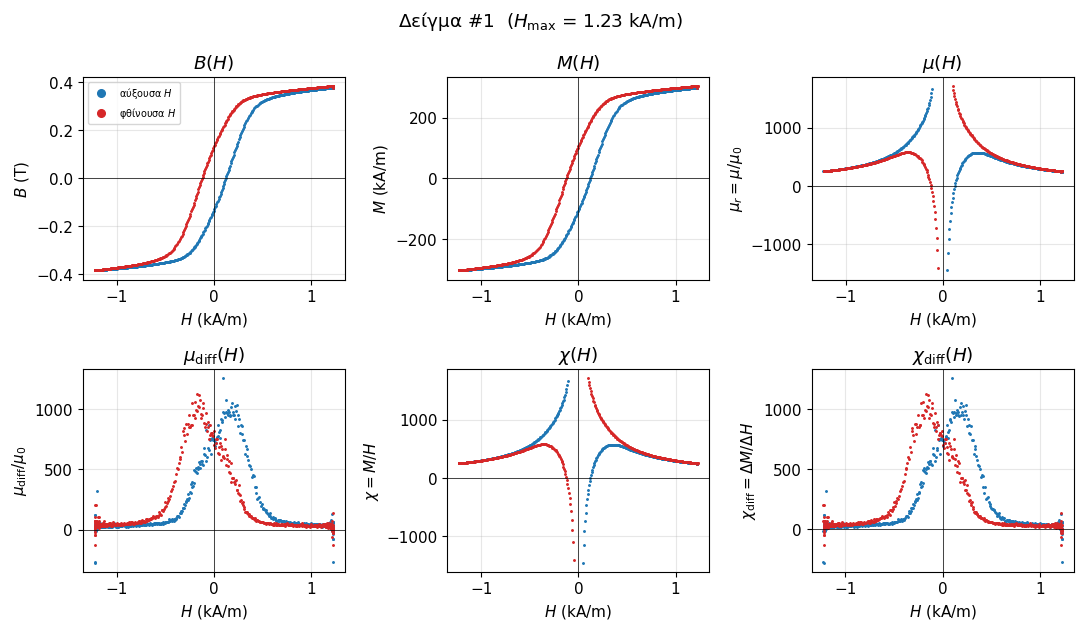

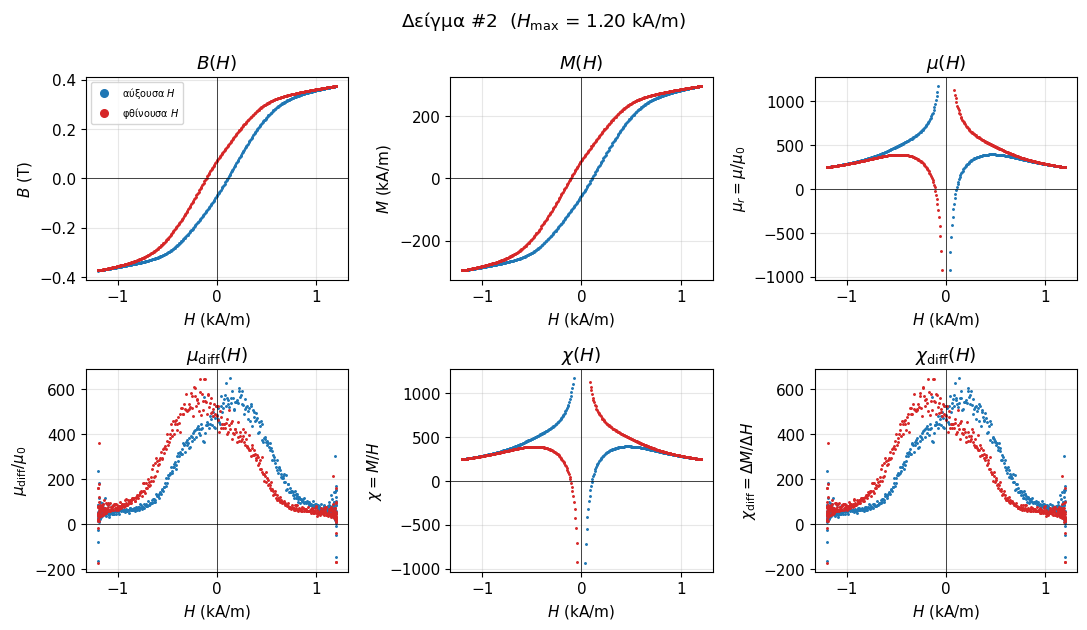

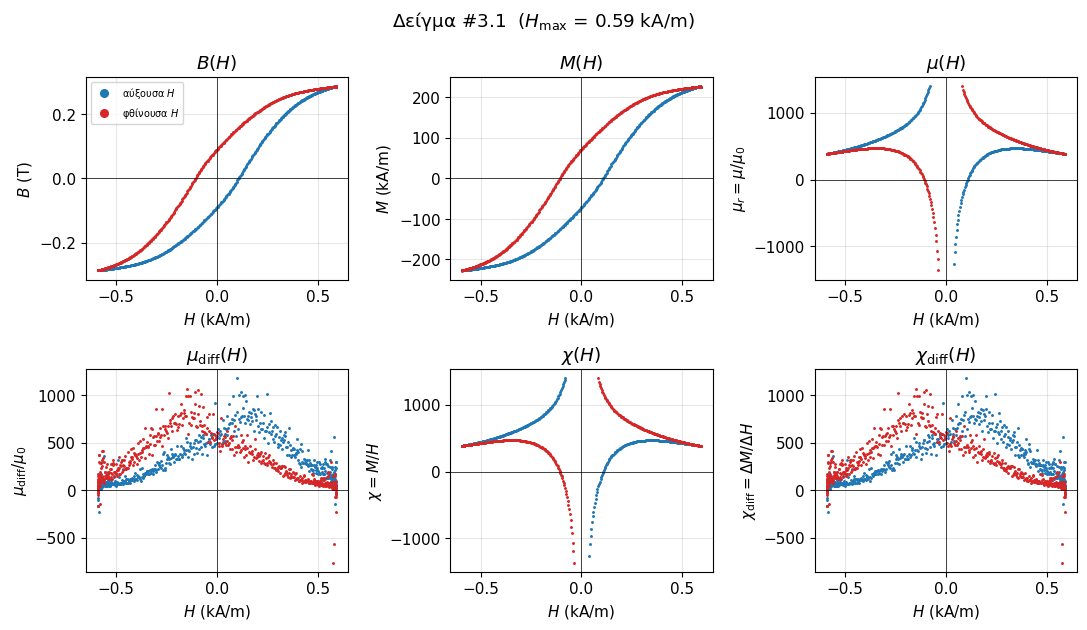

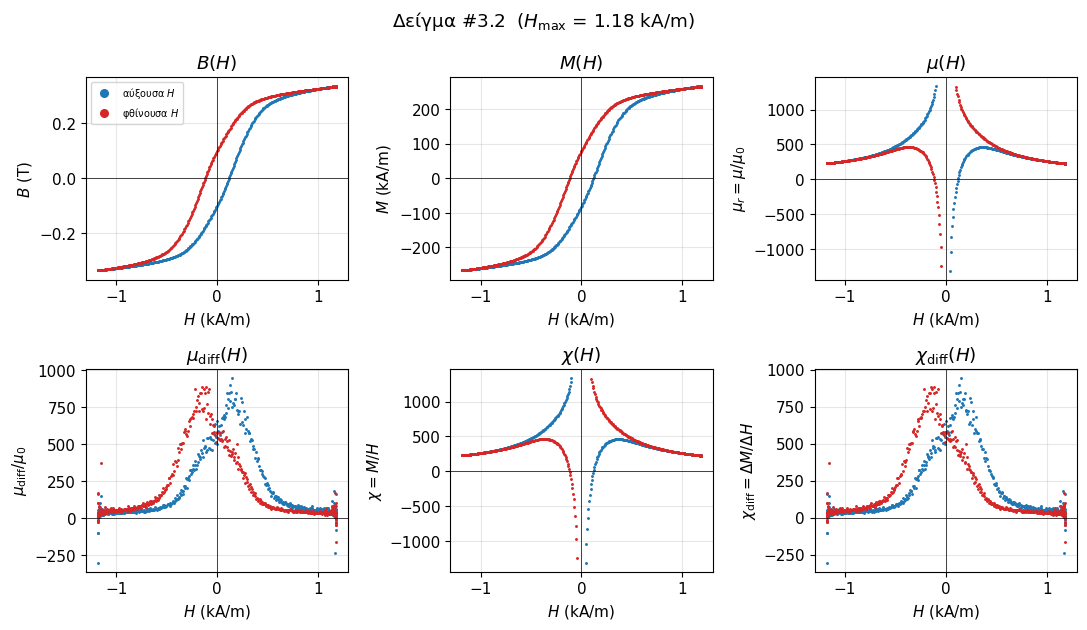

In [9]:
specs = [('B',    'H',  r'$B$ (T)',                          r'$B(H)$',                 ('asc', 'desc')),
         ('M',    'H',  r'$M$ (kA/m)',                       r'$M(H)$',                 ('asc', 'desc')),
         ('mu',   'H',  r'$\mu_r=\mu/\mu_0$',                r'$\mu(H)$',               ('asc', 'desc')),
         ('mud',  'Hm', r'$\mu_{\rm diff}/\mu_0$',           r'$\mu_{\rm diff}(H)$',    ('asc_d', 'desc_d')),
         ('chi',  'H',  r'$\chi=M/H$',                        r'$\chi(H)$',               ('asc', 'desc')),
         ('chid', 'Hm', r'$\chi_{\rm diff}=\Delta M/\Delta H$', r'$\chi_{\rm diff}(H)$', ('asc_d', 'desc_d'))]

for k, q in Q.items():
    H, B = q['H'], q['B']
    sel = q['asc'] & (H > 0) & (B > 0)
    # clip because for H->0 derivatives deviate
    clip = {'mu': 3*np.nanmax(np.where(sel, q['mu'], np.nan)),
            'chi': 3*np.nanmax(np.where(sel, q['chi'], np.nan))}

    fig, axs = plt.subplots(2, 3, figsize=(11, 6.4))
    for ax, (key, xk, yl, title, (m_up, m_dn)) in zip(axs.flat, specs):
        x, y = q[xk]/1e3, q[key].copy()
        if key in clip:
            y[np.abs(y) > clip[key]] = np.nan
        ax.plot(x, np.where(q[m_up], y, np.nan), '.', ms=2.2, color='C0', label=r'αύξουσα $H$')
        ax.plot(x, np.where(q[m_dn], y, np.nan), '.', ms=2.2, color='C3', label=r'φθίνουσα $H$')
        ax.axhline(0, color='k', lw=.5); ax.axvline(0, color='k', lw=.5)
        ax.set_xlabel(r'$H$ (kA/m)'); ax.set_ylabel(yl); ax.set_title(title)
    axs[0, 0].legend(markerscale=5, fontsize=7)
    fig.suptitle(f"Δείγμα #{k}  ($H_{{\\max}}$ = {H.max()/1e3:.2f} kA/m)")
    fig.tight_layout(); fig.savefig(f'figs/sample_{k}.pdf'); plt.show()

## Συγκριτικά γραφήματα (και οι τέσσερις βρόχοι)

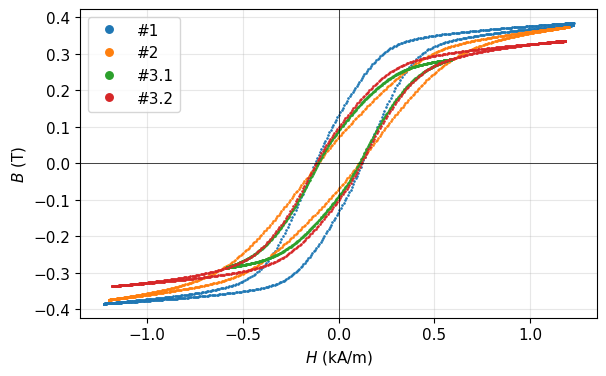

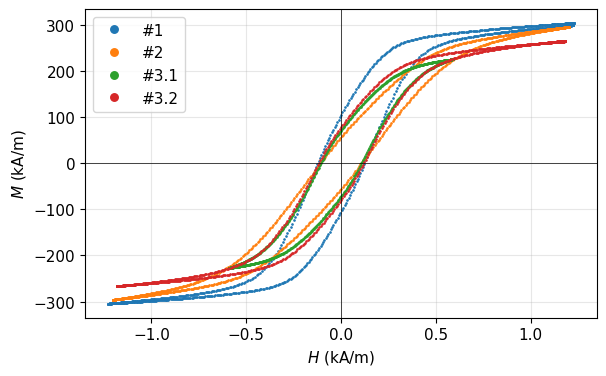

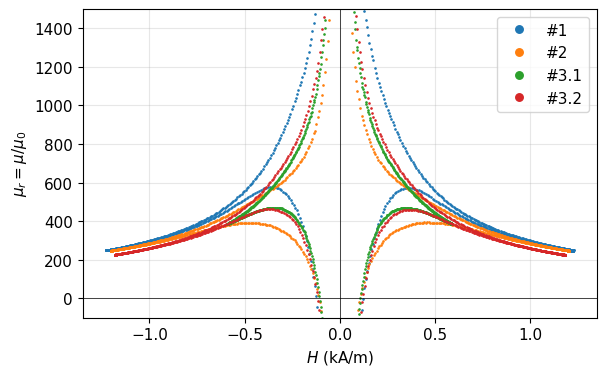

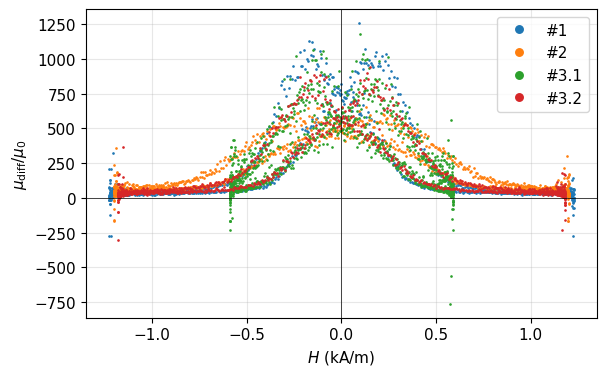

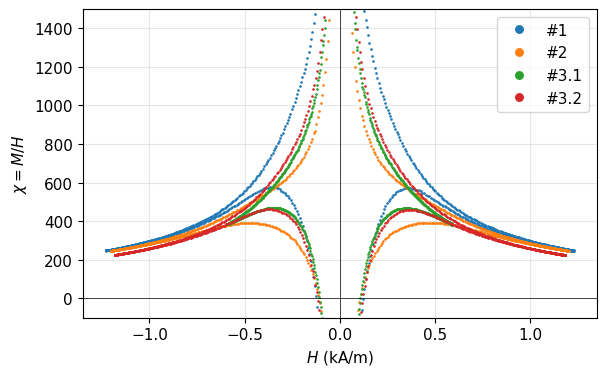

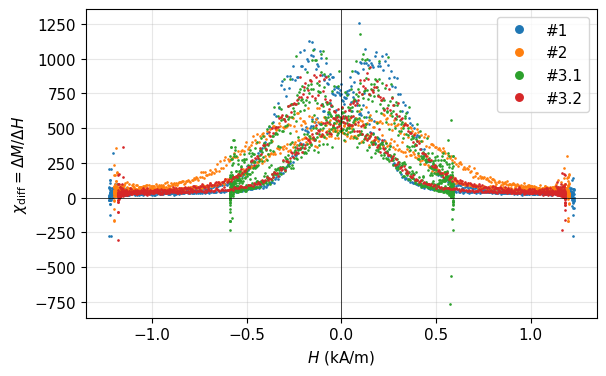

In [6]:
ylims = {'mu': (-100, 1500), 'chi': (-100, 1500)}
for key, xk, yl, title, _ in specs:
    fig, ax = plt.subplots(figsize=(6.2, 3.9))
    for i, (k, q) in enumerate(Q.items()):
        ax.plot(q[xk]/1e3, q[key], '.', ms=1.8, color=f'C{i}', label=f'#{k}')
    ax.axhline(0, color='k', lw=.5); ax.axvline(0, color='k', lw=.5)
    if key in ylims:
        ax.set_ylim(*ylims[key])
    ax.set_xlabel(r'$H$ (kA/m)'); ax.set_ylabel(yl); ax.legend(markerscale=6)
    fig.tight_layout(); fig.savefig(f'figs/cmp_{key}.pdf'); plt.show()